### Workspace for Matt

## Data load, clean and match

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate data directory (relative to notebook: 'data/', with fallback to '../Data_Raw/')
data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
if not data_dir.exists():
    data_dir = Path('Data_Raw')

# Load raw CSV datasets into DataFrames (using first-row headers as column names)
Harris1 = pd.read_csv(data_dir / 'HarrisPartI.csv', na_values=['NA', 'XXXX', 'NONE'])
Harris3 = pd.read_csv(data_dir / 'HarrisPartIII.csv', na_values=['NA', 'XXXX', 'NONE'])
vandenBerg = pd.read_csv(data_dir / 'vandenBerg_table2.csv', na_values=['NA', 'XXXX', 'NONE'])
Krause = pd.read_csv(data_dir / 'Krause21.csv', na_values=['NA', 'XXXX', 'NONE'])

# Strip leading '#' from '#NGC' so vandenBerg.NGC works as a direct attribute
vandenBerg.columns = [col.lstrip('#') for col in vandenBerg.columns]

# Lowercase aliases for convenience
harris1, harris3, vandenberg, krause = Harris1, Harris3, vandenBerg, Krause

# Verify access format: Harris1.ID[4]
print(f"Harris1.ID[4] = '{Harris1.ID[3]}'")
print(f"Loaded shapes: Harris1 {Harris1.shape}, Harris3 {Harris3.shape}, vandenBerg {vandenBerg.shape}, Krause {Krause.shape}")


Harris1.ID[4] = 'Whiting 1'
Loaded shapes: Harris1 (157, 11), Harris3 (157, 13), vandenBerg (55, 13), Krause (61, 8)


In [2]:
"""Run after loading Harris1, Harris3, vandenBerg and Krause.

Creates master and match_report.
"""
import re
from collections import defaultdict

# Abreviation dictionary
NAME_MAP = {
    'RUPRECHT106': 'RUP106',
    'PALOMAR12': 'PAL12',
    'TER8': 'TERZAN8',
}

# normalise name if not na, conform to upper case, check for null identifier. Check dictionary to see for abreviation. returns correct case condition, null identifier or abbreviation
def normalise_name(value):
    if pd.isna(value):
        return None
    key = re.sub(r'\s+', '', str(value)).upper()
    if key in {'', 'NA', 'NAN', 'NONE', 'XXXX'}:
        return None
    return NAME_MAP.get(key, key)

# matches ngc ID
def ngc_number(value, bare_number=False):
    key = normalise_name(value)
    if key is None:
        return pd.NA
    pattern = r'(\d+)(?:\.0+)?' if bare_number else r'NGC(\d+)'
    found = re.fullmatch(pattern, key)
    return int(found.group(1)) if found else pd.NA

# Work on copies; protect original csv files.
sources = {
    'h1': Harris1.copy(),
    'h3': Harris3.copy(),
    'k': Krause.copy(),
    'vb': vandenBerg.copy(),
}
sources['vb'] = sources['vb'].rename(columns={'#NGC': 'NGC'})
primary_column = {'h1': 'ID', 'h3': 'ID', 'k': 'Object', 'vb': 'NGC'}
alias_column = {'h1': 'Name', 'h3': None, 'k': 'AltName', 'vb': 'Name'}

for source, frame in sources.items():
    if not frame.columns.is_unique:
        raise ValueError(f'{source}: duplicate column names need review.')
    original = frame[primary_column[source]]
    numbers = original.map(lambda x: ngc_number(x, bare_number=(source == 'vb')))
    # In vb this converts its existing NGC field to nullable integers.
    # Other sources gain a derived NGC fieldretain original IDs.
    frame['NGC'] = pd.array(numbers, dtype='Int64')

# Build a lookup using Harris primary IDs AND its listed alternative names.
harris_lookup = defaultdict(set)
display_names = {}
for _, row in sources['h1'].iterrows():
    if normalise_name(row['ID']) is None:
        raise ValueError('Harris I contains a missing primary ID.')
    cluster_id = str(row['ID']).strip()
    if cluster_id in display_names:
        raise ValueError(f'Duplicate Harris I ID: {cluster_id}')
    display_names[cluster_id] = (
        str(row['Name']).strip() if normalise_name(row['Name']) else cluster_id
    )
    for value in [row['ID'], row['Name']]:
        key = normalise_name(value)
        if key is not None:
            harris_lookup[key].add(cluster_id)

def lookup_unique(key):
    candidates = harris_lookup.get(key, set())
    if len(candidates) > 1:
        raise ValueError(f'Ambiguous Harris name {key!r}: {sorted(candidates)}')
    return next(iter(candidates)) if candidates else None

records = []
indexed_sources = {}
for source, frame in sources.items():
    common_ids = []
    for row_position, (_, row) in enumerate(frame.iterrows()):
        number = row['NGC']
        primary = row[primary_column[source]]
        alias = row[alias_column[source]] if alias_column[source] else pd.NA
        primary_key = (
            f'NGC{number}' if pd.notna(number) else
            normalise_name(alias if source == 'vb' else primary)
        )
        alias_key = normalise_name(alias)
        primary_match = lookup_unique(primary_key)
        alias_match = lookup_unique(alias_key)

        if primary_match and alias_match and primary_match != alias_match:
            raise ValueError(f'{source} row {row_position}: ID and alias disagree.')
        if pd.notna(number) and alias_match:
            if normalise_name(alias_match) != f'NGC{number}':
                raise ValueError(f'{source} row {row_position}: NGC number conflicts with alias.')

        cluster_id = primary_match or alias_match
        if cluster_id:
            method = 'NGC' if pd.notna(number) and primary_match else (
                'primary name' if primary_match else 'Harris alias'
            )
        else:
            # Source-qualified keys to avoid accidentally merging unresolved objects.
            label = primary_key or alias_key or f'ROW{row_position}'
            cluster_id = f'UNMATCHED:{source}:{label}'
            method = 'unmatched - review'
            display_names[cluster_id] = (
                str(alias).strip() if normalise_name(alias) else
                str(primary).strip() if normalise_name(primary) else cluster_id
            )

        common_ids.append(cluster_id)
        records.append({
            'source': source, 'source_row': row_position,
            'original_id': primary, 'original_alias': alias,
            'cluster_id': cluster_id, 'NGC': number, 'match_method': method,
        })

    if pd.Index(common_ids).has_duplicates:
        repeated = pd.Series(common_ids)[pd.Series(common_ids).duplicated(keep=False)]
        raise ValueError(f'{source}: multiple rows map to one object; review {repeated.tolist()}')
    frame.index = pd.Index(common_ids, name='cluster_id')
    indexed_sources[source] = frame

# Outer alignment keeps every source row
master = pd.concat(indexed_sources, axis=1, join='outer', sort=False)
master.columns.names = ['source', 'quantity']

match_report = pd.DataFrame(records)
match_report['NGC'] = pd.array(match_report['NGC'], dtype='Int64')
meta = pd.DataFrame(index=master.index)
meta['cluster_id'] = master.index.astype('string')
meta['preferred_name'] = pd.Series(display_names, dtype='string').reindex(master.index)
meta['NGC'] = pd.Series(pd.NA, index=master.index, dtype='Int64')
for frame in indexed_sources.values():
    meta['NGC'] = meta['NGC'].fillna(frame['NGC'].reindex(master.index))
meta['matched_to_harris'] = master.index.isin(sources['h1']['ID'].str.strip())
meta.columns = pd.MultiIndex.from_product([['meta'], meta.columns], names=['source', 'quantity'])
master = pd.concat([meta, master], axis=1)

print(f'Master table: {len(master)} clusters, {master.shape[1]} columns')
print('\nMatching summary:')
print(pd.crosstab(match_report['source'], match_report['match_method']).to_string())
unmatched = match_report[match_report['match_method'] == 'unmatched - review']
print('\nUnmatched rows (retained in master):')
print(unmatched[['source', 'original_id', 'original_alias', 'cluster_id']].to_string(index=False))

# Notebook access examples:
# master['h1']                         # All Harris I columns
# master['h3']['v_r']                   # Radial velocities
# master.loc['NGC 104', ('vb', 'Age')]   # One cluster and measurement
# master['meta']['NGC']                 # Nullable integer NGC numbers
# master[[('vb', 'Age'), ('vb', 'FeH')]].dropna()  # Plot-specific sample


Master table: 158 clusters, 52 columns

Matching summary:
match_method  NGC  primary name  unmatched - review
source                                             
h1            104            53                   0
h3            104            53                   0
k              58             3                   0
vb             52             2                   1

Unmatched rows (retained in master):
source original_id original_alias         cluster_id
    vb        <NA>          Arp21 UNMATCHED:vb:ARP21


In [3]:
# save master csv
master.to_csv(data_dir / "master_catalogue.csv", index=True)
""" example on how to load csv
master = pd.read_csv(
    data_dir / "master_catalogue.csv",
    header=[0, 1],
    index_col=0
)

# Restore nullable integer types for NGC numbers
for source in ["meta", "h1", "h3", "k", "vb"]:
    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")

"""

' example on how to load csv\nmaster = pd.read_csv(\n    data_dir / "master_catalogue.csv",\n    header=[0, 1],\n    index_col=0\n)\n\n# Restore nullable integer types for NGC numbers\nfor source in ["meta", "h1", "h3", "k", "vb"]:\n    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")\n\n'

### Data cleaning
Filter out maximally informative data points for analysis, if includes age + Fe/H + R_gc + v_LSR data. Prioritises VandenBerg Data since it includes error and uses better method.

In [11]:
from pathlib import Path
import pandas as pd

# Locate data directory (relative to notebook)
for p in [Path('data'), Path('PHYS3116_Larawag/data'), Path('../data')]:
    if (p / 'master_catalogue.csv').exists():
        data_dir = p
        break

# Read master catalogue
master_raw = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str, encoding='utf-8')
master_raw.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master_raw.columns], names=['source', 'quantity'])
master_raw.index = master_raw.index.str.strip()
master_raw.index.name = 'cluster_id'

# Numeric conversions to identify complete measurements
age_vb = pd.to_numeric(master_raw[('vb', 'Age')], errors='coerce')
age_k  = pd.to_numeric(master_raw[('k', 'Age')], errors='coerce')
feh_vb = pd.to_numeric(master_raw[('vb', 'FeH')], errors='coerce')
feh_k  = pd.to_numeric(master_raw[('k', 'FeH')], errors='coerce')

# VandenBerg primary benchmark + Krause 9-cluster supplement
age = age_vb.combine_first(age_k)
feh = feh_vb.combine_first(feh_k)

# R_gc from Harris I (fallback to vb R_G) & v_LSR from Harris III
rgc   = pd.to_numeric(master_raw[('h1', 'R_gc')], errors='coerce').combine_first(pd.to_numeric(master_raw[('vb', 'R_G')], errors='coerce'))
v_lsr = pd.to_numeric(master_raw[('h3', 'v_LSR')], errors='coerce')

# 4. Filter mask for the 63 clusters
mask_63 = age.notna() & feh.notna() & rgc.notna() & v_lsr.notna()

# 5. Extract filtered and save to data/filtered_catalogue.csv
filtered_catalogue = master_raw.loc[mask_63]
out_path = data_dir / 'filtered_catalogue.csv'
filtered_catalogue.to_csv(out_path, encoding='utf-8')

print(f"Successfully filtered {len(filtered_catalogue)} clusters and saved to: {out_path}")


Successfully filtered 63 clusters and saved to: data\filtered_catalogue.csv


## Data Visualisation

### Exploratory

3D plot of age metalicity galactic distance for visualisation purposes

In [13]:
import plotly.graph_objects as go
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load master catalogue if not already in session
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(
        data_dir / 'master_catalogue.csv',
        header=[0, 1],
        index_col=0
    )

# 2. Extract VandenBerg et al. (2013) data (Circles)
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()

feh_vb = df_vb[('vb', 'FeH')].astype(float)
age_vb = df_vb[('vb', 'Age')].astype(float)
rg_vb = df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float)
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())

# 3. Extract Krause et al. (2021) data (Squares)
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()

feh_k = df_k[('k', 'FeH')].astype(float)
age_k = df_k[('k', 'Age')].astype(float)
rg_k = df_k[('h1', 'R_gc')].astype(float)
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())

# 4. Construct 3D Interactive Plot
fig = go.Figure()

# Trace 1: VandenBerg 
fig.add_trace(go.Scatter3d(
    x=feh_vb,
    y=rg_vb,
    z=age_vb,
    mode='markers',
    name='VandenBerg et al. (2013)',
    text=names_vb,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>VandenBerg</extra>'
    ),
    marker=dict(
        size=6,
        symbol='circle',
        color='#2563eb',  # Vibrant blue
        opacity=0.85,
        line=dict(color='#1e3a8a', width=1)
    )
))

# Trace 2: Krause 
fig.add_trace(go.Scatter3d(
    x=feh_k,
    y=rg_k,
    z=age_k,
    mode='markers',
    name='Krause et al. (2021)',
    text=names_k,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>Krause</extra>'
    ),
    marker=dict(
        size=6,
        symbol='square',
        color='#ef4444',  # Vibrant red/coral
        opacity=0.85,
        line=dict(color='#991b1b', width=1)
    )
))

# 5. Configure 3D Axes, Camera Angle, and Layout
fig.update_layout(
    title=dict(
        text='<b>3D Globular Cluster Space: Metallicity vs. Distance vs. Age</b>',
        x=0.5,
        y=0.95,
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(
            title='Metallicity [Fe/H] (dex)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        yaxis=dict(
            title='Galactocentric Distance R_gc (kpc)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        zaxis=dict(
            title='Age (Gyr)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        camera=dict(
            eye=dict(x=1.7, y=-1.7, z=1.2)  # Initial 3D isometric view
        ),
        aspectmode='manual',
        aspectratio=dict(x=1.2, y=1.2, z=1.0)
    ),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255, 255, 255, 0.85)',
        bordercolor='#cbd5e1',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()


Not very clear, see plot_3d_amr.m, matlab code for better plot

### Age Metalicity


Shows vandenberg and krause data for comparison with colorbar showing galactic distance

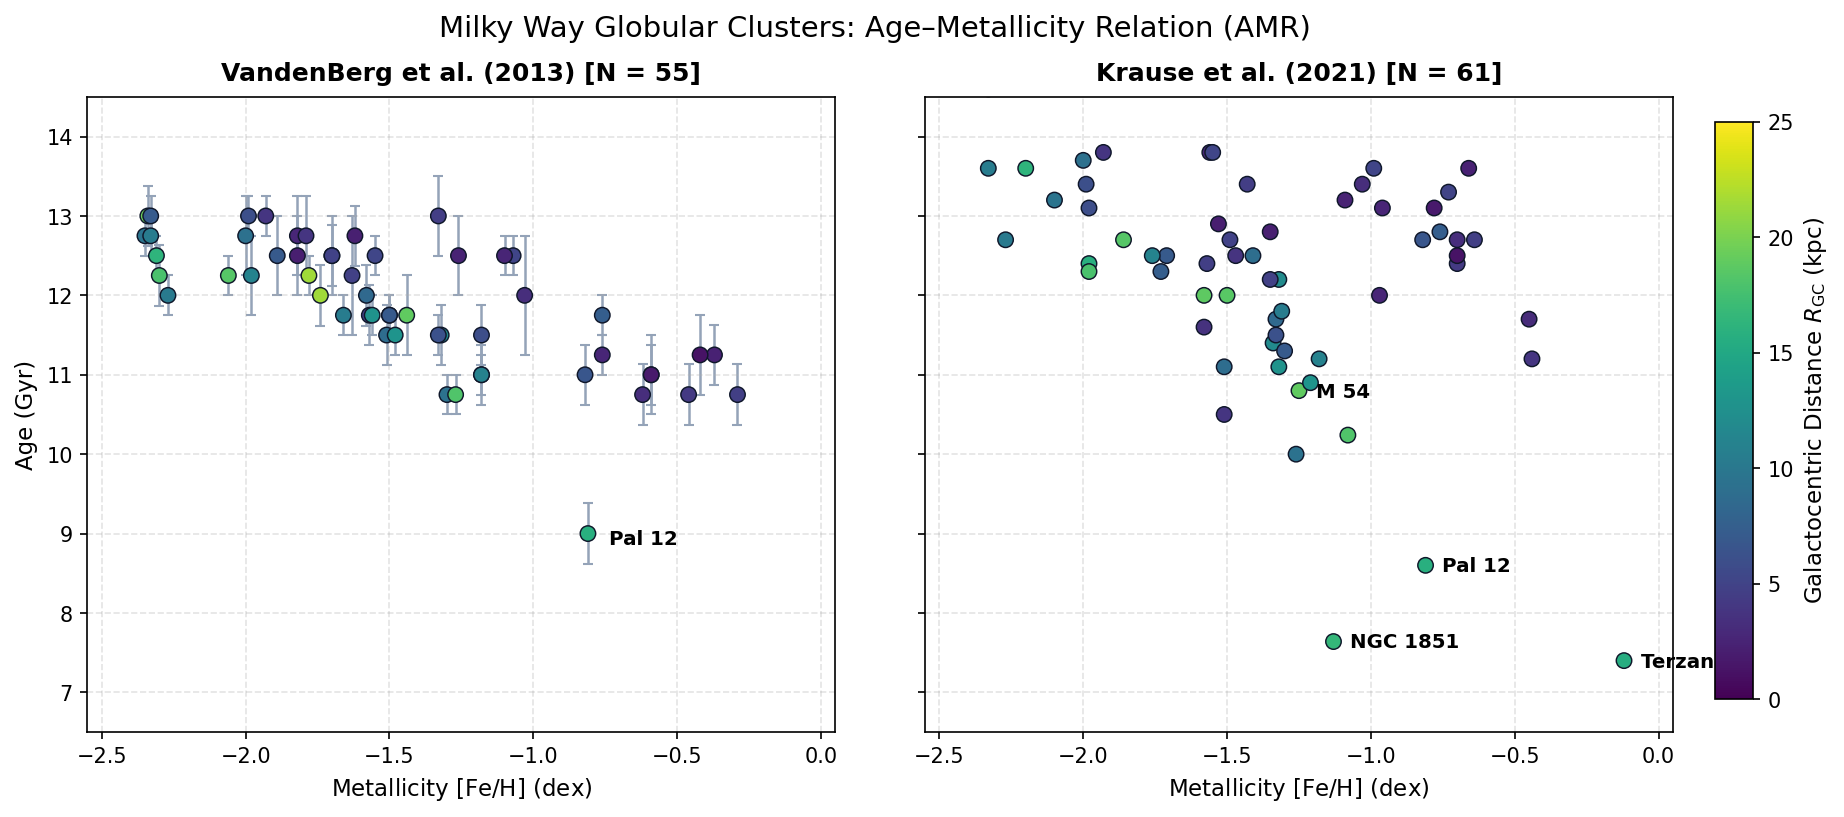

In [14]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0)
# Samples
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150, sharey=True)
# Panel 1: VandenBerg (2013)
ax1.errorbar(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    yerr=df_vb[('vb', 'Age_err')].astype(float),
    fmt='none', ecolor='#94a3b8', elinewidth=1.2, capsize=2.5, zorder=1
)
sc1 = ax1.scatter(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    c=df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax1.set_title(f'VandenBerg et al. (2013) [N = {len(df_vb)}]', fontsize=12, fontweight='bold', pad=8)
ax1.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax1.set_ylabel(r'Age (Gyr)', fontsize=11)
ax1.set_xlim(-2.55, 0.05)
ax1.set_ylim(6.5, 14.5)
ax1.grid(True, linestyle='--', alpha=0.35)
p12 = df_vb[names_vb == 'Pal 12']
if not p12.empty:
    ax1.annotate('Pal 12', (float(p12[('vb', 'FeH')].iloc[0]), float(p12[('vb', 'Age')].iloc[0])),
                 xytext=(10, -5), textcoords='offset points', fontsize=9.5, fontweight='bold')
# Panel 2: Krause et al. (2021)
sc2 = ax2.scatter(
    df_k[('k', 'FeH')].astype(float), df_k[('k', 'Age')].astype(float),
    c=df_k[('h1', 'R_gc')].astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax2.set_title(f'Krause et al. (2021) [N = {len(df_k)}]', fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax2.set_xlim(-2.55, 0.05)
ax2.grid(True, linestyle='--', alpha=0.35)
for name in ['Terzan 7', 'Pal 12', 'NGC 1851', 'M 54']:
    m = df_k[names_k == name]
    if not m.empty:
        ax2.annotate(name, (float(m[('k', 'FeH')].iloc[0]), float(m[('k', 'Age')].iloc[0])),
                     xytext=(8, -3), textcoords='offset points', fontsize=9.5, fontweight='bold')
# shared colorbar
fig.subplots_adjust(right=0.88, wspace=0.12)
cbar_ax = fig.add_axes([0.90, 0.15, 0.018, 0.7])
cbar = fig.colorbar(sc2, cax=cbar_ax)
cbar.set_label(r'Galactocentric Distance $R_{\mathrm{GC}}$ (kpc)', fontsize=11)
fig.suptitle('Milky Way Globular Clusters: Age–Metallicity Relation (AMR)', fontsize=14, y=0.98)
plt.show()


### Kinematics



In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

# =============================================================================
# 1. Class Definitions
# =============================================================================
class gc_kinematics:
    """Stores kinematic and spatial quantities for an individual globular cluster."""
    def __init__(self, ID, v_gsr, x, y, z, p, R_gc=None, R_cyl=None, v_lsr=None,
                 resid=None, V_rot=None, sigma_V=None):
        self.ID = ID            # Primary cluster identifier (e.g. 'NGC 104')
        self.v_gsr = v_gsr      # Line-of-sight velocity in Galactic Standard of Rest (km/s)
        self.x = x              # Galactocentric Cartesian X (kpc; Sun at x = -8.0)
        self.y = y              # Galactocentric Cartesian Y (kpc; direction of rotation)
        self.z = z              # Galactocentric Cartesian Z (kpc; height above disk)
        self.p = p              # Projection factor = eHat_phi dot eHat_los
        self.R_gc = R_gc        # 3D Galactocentric distance from Harris I (kpc)
        self.R_cyl = R_cyl      # In-plane cylindrical radius = sqrt(x^2 + y^2) (kpc)
        self.v_lsr = v_lsr      # Velocity relative to Local Standard of Rest (km/s)
        
        # Linear regression through origin parameters
        self.resid = resid      # Velocity residual: v_gsr - V_rot * p (km/s; non-circular motion)
        self.V_rot = V_rot      # Fitted system circular rotation velocity (km/s)
        self.sigma_V = sigma_V  # Uncertainty in fitted V_rot (km/s)
    def __getitem__(self, idx):
        """Allows positional index access: [0]=ID, [1]=v_gsr, [2]=x, [3]=y, [4]=z, [5]=p, [6]=resid."""
        fields = [self.ID, self.v_gsr, self.x, self.y, self.z, self.p, self.resid, self.V_rot, self.sigma_V]
        return fields[idx]
    def __repr__(self):
        r_str = f"{self.resid:.1f}" if self.resid is not None else "None"
        return (f"gc_kinematics(ID='{self.ID}', v_gsr={self.v_gsr:.1f} km/s, "
                f"x={self.x:.2f}, y={self.y:.2f}, z={self.z:.2f}, p={self.p:.3f}, resid={r_str})")

class KinematicsCatalogue:
    """
    Hybrid container for gc_kinematics instances.
    Supports:
      - Positional index:  kinematics_catalogue[0]
      - String key lookup: kinematics_catalogue['NGC 104'] or kinematics_catalogue['NGC104']
      - Dot attribute:     kinematics_catalogue.NGC_104 or kinematics_catalogue.NGC104
      - Standard loops:    for gc in kinematics_catalogue: ...
    """
    def __init__(self):
        self._list = []
        self._dict = {}

    def append(self, item):
        self._list.append(item)
        key_raw = str(item.ID).strip()
        key_norm = key_raw.replace(' ', '').upper()
        key_attr = key_raw.replace(' ', '_').replace('-', '_')
        
        # Store in internal dictionary for fast string lookup
        self._dict[key_raw] = item
        self._dict[key_norm] = item
        self._dict[key_attr] = item
        
        # Expose direct dot-attribute access
        setattr(self, key_attr, item)
        if key_norm != key_attr:
            setattr(self, key_norm, item)

    def __getitem__(self, key):
        if isinstance(key, (int, slice)):
            return self._list[key]
        elif isinstance(key, str):
            k = key.strip()
            if k in self._dict:
                return self._dict[k]
            k_norm = k.replace(' ', '').upper()
            if k_norm in self._dict:
                return self._dict[k_norm]
            raise KeyError(f"Cluster '{key}' not found in kinematics catalogue.")
        raise TypeError(f"Invalid key type: {type(key)}")

    def __len__(self):
        return len(self._list)

    def __iter__(self):
        return iter(self._list)

    def to_dataframe(self):
        """Export as a clean pandas DataFrame."""
        return pd.DataFrame([{
            'ID': gc.ID,
            'v_gsr': gc.v_gsr,
            'x': gc.x,
            'y': gc.y,
            'z': gc.z,
            'p': gc.p,
            'R_gc': gc.R_gc,
            'R_cyl': gc.R_cyl,
            'v_lsr': gc.v_lsr
        } for gc in self._list])


# =============================================================================
# 2. Ingestion & Kinematics Processing Loop
# =============================================================================
# Locate data directory
for p in [Path('data'), Path('PHYS3116_Larawag/data'), Path('../data')]:
    if (p / 'master_catalogue.csv').exists():
        data_dir = p
        break

master = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str, encoding='utf-8')
master.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master.columns])
master.index = master.index.str.strip()

# Solar circular orbital velocity in km/s
v0 = 220.0

# Initialise catalogue
kinematics_catalogue = KinematicsCatalogue()

for cluster_id, row in master.iterrows():
    cid = str(cluster_id).strip()
    if cid in ['', 'cluster_id', 'nan', 'None']:
        continue

    # Extract required quantities from Harris I & III
    v_lsr_val = pd.to_numeric(row[('h3', 'v_LSR')], errors='coerce')
    L_val     = pd.to_numeric(row[('h1', 'L')], errors='coerce')
    B_val     = pd.to_numeric(row[('h1', 'B')], errors='coerce')
    X_val     = pd.to_numeric(row[('h1', 'X')], errors='coerce')
    Y_val     = pd.to_numeric(row[('h1', 'Y')], errors='coerce')
    Z_val     = pd.to_numeric(row[('h1', 'Z')], errors='coerce')
    R_Sun_val = pd.to_numeric(row[('h1', 'R_Sun')], errors='coerce')
    R_gc_val  = pd.to_numeric(row[('h1', 'R_gc')], errors='coerce')

    # If any required data is NaN, skip (exclude from new catalogue)
    req_vals = [v_lsr_val, L_val, B_val, X_val, Y_val, Z_val, R_Sun_val, R_gc_val]
    if any(np.isnan(v) for v in req_vals):
        continue

    # 1. Line-of-sight velocity in Galactic Standard of Rest (GSR)
    L_rad = np.radians(L_val)
    B_rad = np.radians(B_val)
    v_gsr = v_lsr_val + v0 * np.sin(L_rad) * np.cos(B_rad)

    # 2. Galactocentric Cartesian coordinates (kpc; Sun at x = -8.0, y = 0, z = 0)
    x = X_val - 8.0
    y = Y_val
    z = Z_val

    # 3. Cylindrical radius in Galactic plane
    R_cyl = np.sqrt(x**2 + y**2)

    # 4. Projection factor p = eHat_phi dot eHat_los
    if R_cyl > 0 and R_Sun_val > 0:
        eHat_phi = np.array([y, -x, 0.0]) / R_cyl
        eHat_los = np.array([X_val, Y_val, Z_val]) / R_Sun_val
        p = float(np.dot(eHat_phi, eHat_los))
    else:
        p = 0.0

    # Instantiate class and append to catalogue
    gc = gc_kinematics(ID=cid, v_gsr=v_gsr, x=x, y=y, z=z, p=p, R_gc=R_gc_val, R_cyl=R_cyl, v_lsr=v_lsr_val)
    kinematics_catalogue.append(gc)

print(f"Successfully processed {len(kinematics_catalogue)} clusters into kinematics_catalogue.")
print(f" - Access example by index [0]:                {kinematics_catalogue[0]}")
print(f" - Access example by string ['NGC 104'].v_gsr: {kinematics_catalogue['NGC 104'].v_gsr:.2f} km/s")
print(f" - Access example by dot-attribute .NGC_104.p: {kinematics_catalogue.NGC_104.p:.3f}")


Successfully processed 143 clusters into kinematics_catalogue.
 - Access example by index [0]:                gc_kinematics(ID='NGC 104', v_gsr=-153.0 km/s, x=-6.10, y=-2.60, z=-3.10, p=-0.697, resid=None)
 - Access example by string ['NGC 104'].v_gsr: -152.97 km/s
 - Access example by dot-attribute .NGC_104.p: -0.697


In [2]:
# =============================================================================
# TEST 1: Verify sqrt(x^2 + y^2 + z^2) == R_gc for the first 10 entries
# =============================================================================
print("=" * 65)
print("TEST 1: Coordinate check: sqrt(x^2 + y^2 + z^2) vs R_gc (First 10)")
print("=" * 65)
print(f"{'ID':<12} {'R_gc (kpc)':<14} {'Calculated (kpc)':<18} {'Error (kpc)':<12}")
print("-" * 65)

for gc in kinematics_catalogue[:10]:
    calc_rgc = np.sqrt(gc.x**2 + gc.y**2 + gc.z**2)
    err = calc_rgc - gc.R_gc
    print(f"{gc.ID:<12} {gc.R_gc:<14.3f} {calc_rgc:<18.3f} {err:<+12.4f}")

print("\nNote: Tiny ~0.01 - 0.05 kpc discrepancies are expected due to rounding")
print("of Harris X, Y, Z coordinates to 1 decimal place.")

# =============================================================================
# TEST 2: Sign check for eHat_phi at Sun's position (x = -8.0, y = 0.0)
# =============================================================================
print("\n" + "=" * 65)
print("TEST 2: Verify eHat_phi sign at Sun's position (x = -8, y = 0)")
print("=" * 65)

sun_x, sun_y = -8.0, 0.0
sun_R_cyl = np.sqrt(sun_x**2 + sun_y**2)
sun_eHat_phi = np.array([sun_y, -sun_x, 0.0]) / sun_R_cyl

print(f"Formula (y, -x, 0)/R_cyl at Sun gives: ({sun_eHat_phi[0]:.1f}, {sun_eHat_phi[1]:.1f}, {sun_eHat_phi[2]:.1f})")
assert np.allclose(sun_eHat_phi, [0.0, 1.0, 0.0]), "Error: eHat_phi must point in +Y direction!"
print("PASSED: Points in the +Y direction (direction of Solar/disk rotation).")


TEST 1: Coordinate check: sqrt(x^2 + y^2 + z^2) vs R_gc (First 10)
ID           R_gc (kpc)     Calculated (kpc)   Error (kpc) 
-----------------------------------------------------------------
NGC 104      7.400          7.320              -0.0802     
NGC 288      12.000         12.034             +0.0341     
NGC 362      9.400          9.405              +0.0053     
Whiting 1    34.500         34.545             +0.0455     
NGC 1261     18.100         18.133             +0.0334     
Pal 1        17.200         17.251             +0.0514     
AM 1         124.600        124.642            +0.0417     
Eridanus     95.000         94.998             -0.0022     
Pal 2        35.000         34.946             -0.0542     
NGC 1851     16.600         16.603             +0.0030     

Note: Tiny ~0.01 - 0.05 kpc discrepancies are expected due to rounding
of Harris X, Y, Z coordinates to 1 decimal place.

TEST 2: Verify eHat_phi sign at Sun's position (x = -8, y = 0)
Formula (y, -x, 0)/R_

In [9]:
# =============================================================================
# Least-Squares Fit Through Origin: v_GSR = V_rot * p
# =============================================================================
# Extract arrays of p and v_gsr across all clusters in catalogue
p_vals     = np.array([gc.p for gc in kinematics_catalogue])
v_gsr_vals = np.array([gc.v_gsr for gc in kinematics_catalogue])
N          = len(kinematics_catalogue)

# 1. Slope: V_rot = sum(p * v_GSR) / sum(p^2)
sum_p2     = np.sum(p_vals**2)
sum_p_vgsr = np.sum(p_vals * v_gsr_vals)
V_rot      = sum_p_vgsr / sum_p2

# 2. Residuals for each cluster: resid = v_GSR - V_rot * p (measures non-circular motion)
resid_vals = v_gsr_vals - V_rot * p_vals

# 3. Standard error of residuals (degrees of freedom = N - 1 for 1 parameter through origin)
sigma_resid = np.sqrt(np.sum(resid_vals**2) / (N - 1))

# 4. Formal uncertainty in fitted rotation velocity: sigma_V = sigma_resid / sqrt(sum(p^2))
sigma_V = sigma_resid / np.sqrt(sum_p2)

# =============================================================================
# Assign fitted quantities back to each cluster and to catalogue container
# =============================================================================
for gc, r in zip(kinematics_catalogue, resid_vals):
    gc.resid   = float(r)
    gc.V_rot   = float(V_rot)
    gc.sigma_V = float(sigma_V)

# Store population-level parameters on the catalogue instance as well
kinematics_catalogue.V_rot       = float(V_rot)
kinematics_catalogue.sigma_V     = float(sigma_V)
kinematics_catalogue.sigma_resid = float(sigma_resid)

# =============================================================================
# Output Results
# =============================================================================
print("=" * 65)
print("KINEMATIC FIT RESULTS (Least Squares Through Origin)")
print("=" * 65)
print(f"Number of clusters (N):          {N}")
print(f"Bulk Rotation Velocity (V_rot):   {V_rot:.2f} ± {sigma_V:.2f} km/s")
print(f"Velocity Dispersion (sigma_resid): {sigma_resid:.2f} km/s")
print("-" * 65)

# Display sample access tests
print(f"Access via dot-notation: kinematics_catalogue.NGC_104.resid = {kinematics_catalogue.NGC_104.resid:+.1f} km/s")
print(f"Access via catalogue:    kinematics_catalogue.V_rot         = {kinematics_catalogue.V_rot:.2f} km/s")

# Highlight top 5 strongest retrograde / non-circular outliers (|resid| > 200 km/s)
print("\n" + "=" * 65)
print("TOP KINEMATIC OUTLIERS (Candidates with Extreme Non-Circular Motion)")
print("=" * 65)
print(f"{'ID':<12} {'v_GSR (km/s)':<14} {'p':<10} {'V_rot*p (km/s)':<16} {'resid (km/s)':<14}")
print("-" * 65)

sorted_by_abs_resid = sorted(kinematics_catalogue, key=lambda gc: abs(gc.resid), reverse=True)
for gc in sorted_by_abs_resid[:10]:
    v_rot_p = gc.V_rot * gc.p
    print(f"{gc.ID:<12} {gc.v_gsr:<+14.1f} {gc.p:<+10.3f} {v_rot_p:<+16.1f} {gc.resid:<+14.1f}")


KINEMATIC FIT RESULTS (Least Squares Through Origin)
Number of clusters (N):          143
Bulk Rotation Velocity (V_rot):   73.75 ± 18.51 km/s
Velocity Dispersion (sigma_resid): 123.78 km/s
-----------------------------------------------------------------
Access via dot-notation: kinematics_catalogue.NGC_104.resid = -101.6 km/s
Access via catalogue:    kinematics_catalogue.V_rot         = 73.75 km/s

TOP KINEMATIC OUTLIERS (Candidates with Extreme Non-Circular Motion)
ID           v_GSR (km/s)   p          V_rot*p (km/s)   resid (km/s)  
-----------------------------------------------------------------
Djorg 1      -367.7         -0.083     -6.1             -361.6        
NGC 3201     +267.1         -0.888     -65.5            +332.7        
NGC 6287     -278.6         +0.000     +0.0             -278.6        
NGC 6934     -234.3         +0.511     +37.7            -271.9        
NGC 6981     -229.6         +0.430     +31.7            -261.3        
NGC 6101     +214.7         -0.498 

Notes:
- |p| < 0.5 is kinematically uninformativ for rotation 

In [10]:
# =============================================================================
# Filter for Informative Sightlines: |p| > 0.5
# =============================================================================
# Filter the kinematics catalogue
high_p_clusters = [gc for gc in kinematics_catalogue if abs(gc.p) > 0.5]

print("=" * 70)
print(f"HIGH-PROJECTION SUBSET: |p| > 0.5 ({len(high_p_clusters)} of {len(kinematics_catalogue)} clusters)")
print("=" * 70)
print("Sightlines with |p| <= 0.5 point roughly toward/away from the Galactic centre")
print("or poles, where circular rotation has almost zero projection along the line of sight.")
print("Restricting to |p| > 0.5 isolates clusters with high kinematic sensitivity.\n")

# Build a clean DataFrame for inspection and plotting
data_high_p = []
for gc in high_p_clusters:
    # Inferred azimuthal velocity along the circular direction: v_phi ~ v_GSR / p
    v_phi_est = gc.v_gsr / gc.p
    kin_class = "Prograde" if v_phi_est > 0 else "Retrograde"
    
    data_high_p.append({
        'ID': gc.ID,
        'p': gc.p,
        'v_GSR (km/s)': round(gc.v_gsr, 1),
        'V_rot*p (km/s)': round(gc.V_rot * gc.p, 1),
        'resid (km/s)': round(gc.resid, 1),
        'v_phi_est (km/s)': round(v_phi_est, 1),
        'Orbit': kin_class,
        'R_gc (kpc)': round(gc.R_gc, 1),
        'z (kpc)': round(gc.z, 1)
    })

df_high_p = pd.DataFrame(data_high_p)

# Sort by absolute residual magnitude (most extreme non-circular outliers first)
df_high_p = df_high_p.sort_values(by='resid (km/s)', key=abs, ascending=False).reset_index(drop=True)

# -----------------------------------------------------------------------------
# Summary Breakdown & Re-fit Check
# -----------------------------------------------------------------------------
p_sub = np.array([gc.p for gc in high_p_clusters])
v_sub = np.array([gc.v_gsr for gc in high_p_clusters])
N_sub = len(high_p_clusters)

V_rot_sub = np.sum(p_sub * v_sub) / np.sum(p_sub**2)
sigma_resid_sub = np.sqrt(np.sum((v_sub - V_rot_sub * p_sub)**2) / (N_sub - 1))
sigma_V_sub = sigma_resid_sub / np.sqrt(np.sum(p_sub**2))

print(f"Orbit Breakdown (|p| > 0.5):")
print(f" - Prograde clusters  (v_phi_est > 0): {sum(df_high_p['Orbit'] == 'Prograde')}")
print(f" - Retrograde clusters (v_phi_est < 0): {sum(df_high_p['Orbit'] == 'Retrograde')}")
print(f"\nRobustness Check (Re-fit V_rot using only |p| > 0.5):")
print(f" - V_rot (|p| > 0.5) = {V_rot_sub:.2f} ± {sigma_V_sub:.2f} km/s  (Full sample was {kinematics_catalogue.V_rot:.2f} km/s)")
print("=" * 70)

# Display table
display(df_high_p)


HIGH-PROJECTION SUBSET: |p| > 0.5 (60 of 143 clusters)
Sightlines with |p| <= 0.5 point roughly toward/away from the Galactic centre
or poles, where circular rotation has almost zero projection along the line of sight.
Restricting to |p| > 0.5 isolates clusters with high kinematic sensitivity.

Orbit Breakdown (|p| > 0.5):
 - Prograde clusters  (v_phi_est > 0): 39
 - Retrograde clusters (v_phi_est < 0): 21

Robustness Check (Re-fit V_rot using only |p| > 0.5):
 - V_rot (|p| > 0.5) = 72.41 ± 18.68 km/s  (Full sample was 73.75 km/s)


,ID,p,v_GSR (km/s),V_rot*p (km/s),resid (km/s),v_phi_est (km/s),Orbit,R_gc (kpc),z (kpc)
0,NGC 3201,-0.888475,267.1,-65.5,332.7,-300.7,Retrograde,8.8,0.7
1,NGC 6934,0.510569,-234.3,37.7,-271.9,-458.8,Retrograde,12.8,-5.1
2,NGC 6144,-0.829732,172.2,-61.2,233.4,-207.5,Retrograde,2.7,2.4
3,NGC 4590,-0.682945,-251.4,-50.4,-201.0,368.1,Prograde,10.2,6.0
4,NGC 6333,0.930780,260.7,68.6,192.0,280.1,Prograde,1.7,1.5
5,IC 1276,0.821778,250.6,60.6,190.0,305.0,Prograde,3.7,0.5
6,NGC 6535,0.988584,-101.6,72.9,-174.5,-102.7,Retrograde,3.9,1.2
7,NGC 6273,-0.528398,131.9,-39.0,170.9,-249.7,Retrograde,1.7,1.4
8,Terzan 2,-0.754247,102.8,-55.6,158.4,-136.3,Retrograde,0.8,0.3
9,NGC 7099,0.620002,-110.9,45.7,-156.6,-178.8,Retrograde,7.1,-5.9


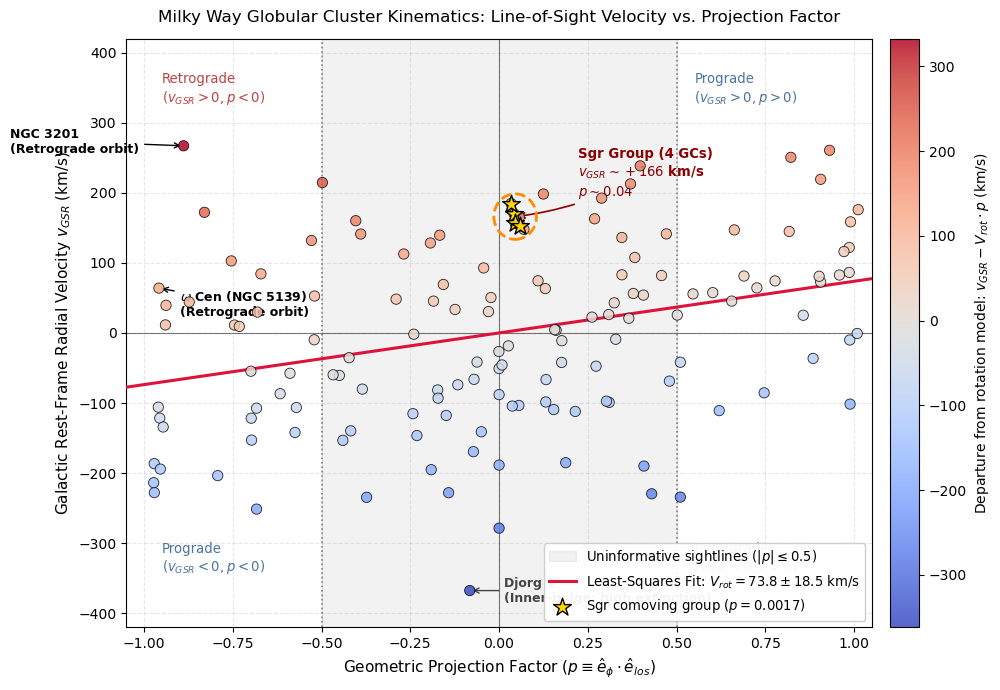

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np

# =============================================================================
# Cell 1: Galactic Rotation Fit — v_GSR vs. Projection Factor p
# =============================================================================
fig, ax = plt.subplots(figsize=(10.5, 7))

# 1. Extract plotting arrays and ensure fit quantities exist
p_arr     = np.array([gc.p for gc in kinematics_catalogue])
v_gsr_arr = np.array([gc.v_gsr for gc in kinematics_catalogue])
V_rot_val = getattr(kinematics_catalogue, 'V_rot', None)

if V_rot_val is None:
    V_rot_val   = np.sum(p_arr * v_gsr_arr) / np.sum(p_arr**2)
    resid_calc  = v_gsr_arr - V_rot_val * p_arr
    sigma_resid = np.sqrt(np.sum(resid_calc**2) / (len(p_arr) - 1))
    sigma_V     = sigma_resid / np.sqrt(np.sum(p_arr**2))
    resid_arr   = resid_calc
else:
    sigma_V   = kinematics_catalogue.sigma_V
    resid_arr = np.array([getattr(gc, 'resid', gc.v_gsr - V_rot_val * gc.p) for gc in kinematics_catalogue])

# 2. Shaded uninformative sightlines (|p| <= 0.5)
ax.axvspan(-0.5, 0.5, color='gray', alpha=0.10, label=r'Uninformative sightlines ($|p| \leq 0.5$)')
ax.axvline(0.5,  color='gray', linestyle=':', lw=1.2)
ax.axvline(-0.5, color='gray', linestyle=':', lw=1.2)
ax.axhline(0, color='black', lw=0.8, alpha=0.5)
ax.axvline(0, color='black', lw=0.8, alpha=0.5)

# 3. Model rotation fit line: v_GSR = V_rot * p
p_fit = np.linspace(-1.05, 1.05, 100)
ax.plot(p_fit, V_rot_val * p_fit, color='crimson', lw=2.2, zorder=3,
        label=rf'Least-Squares Fit: $V_{{rot}} = {V_rot_val:.1f} \pm {sigma_V:.1f}$ km/s')

# 4. Main cluster sample colored by departure from rotation model
sc = ax.scatter(p_arr, v_gsr_arr, c=resid_arr, cmap='coolwarm', s=55,
                edgecolors='black', linewidth=0.6, alpha=0.85, zorder=4)

# 5. HEADLINE DETECTION: Highlight Sagittarius comoving group (M 54, Terzan 7, Terzan 8, Arp 2)
sgr_ids = ['NGC 6715', 'Terzan 7', 'Terzan 8', 'Arp 2']
sgr_p   = [kinematics_catalogue[cid].p for cid in sgr_ids]
sgr_v   = [kinematics_catalogue[cid].v_gsr for cid in sgr_ids]

ax.scatter(sgr_p, sgr_v, color='gold', marker='*', s=180, edgecolors='black',
           linewidths=1.0, zorder=6, label=r'Sgr comoving group ($p = 0.0017$)')

# Orange dashed ellipse around Sgr knot
ellipse = Ellipse((np.mean(sgr_p), np.mean(sgr_v)), width=0.12, height=65,
                  angle=0, edgecolor='darkorange', facecolor='none', lw=2.0, linestyle='--', zorder=7)
ax.add_patch(ellipse)

ax.annotate(r'Sgr Group (4 GCs)' + '\n' + r'$v_{GSR} \sim +166$ km/s' + '\n' + r'$p \sim 0.04$',
            xy=(np.mean(sgr_p), np.mean(sgr_v)), xytext=(45, 15), textcoords='offset points',
            fontsize=9.5, fontweight='bold', color='darkred',
            arrowprops=dict(arrowstyle='->', lw=1.2, color='darkred', connectionstyle='arc3,rad=-0.1'))

# 6. Literature retrograde outliers (NGC 3201, omega Cen)
ax.annotate('NGC 3201\n(Retrograde orbit)',
            xy=(kinematics_catalogue['NGC 3201'].p, kinematics_catalogue['NGC 3201'].v_gsr),
            xytext=(-125, -5), textcoords='offset points',
            fontsize=9, fontweight='bold',
            arrowprops=dict(arrowstyle='->', lw=1.0, color='black'))

ax.annotate(r'$\omega$ Cen (NGC 5139)' + '\n' + '(Retrograde orbit)',
            xy=(kinematics_catalogue['NGC 5139'].p, kinematics_catalogue['NGC 5139'].v_gsr),
            xytext=(15, -20), textcoords='offset points',
            fontsize=9, fontweight='bold',
            arrowprops=dict(arrowstyle='->', lw=1.0, color='black'))

# 7. Conspicuous outlier Djorg 1
ax.annotate('Djorg 1\n(Inner-bulge; high extinction)',
            xy=(kinematics_catalogue['Djorg 1'].p, kinematics_catalogue['Djorg 1'].v_gsr),
            xytext=(25, -8), textcoords='offset points',
            fontsize=9, fontweight='bold', color='#444444',
            arrowprops=dict(arrowstyle='->', lw=1.0, color='#444444'))

# 8. Quadrant labels (Prograde vs. Retrograde)
ax.text(0.55, 330, 'Prograde\n($v_{GSR} > 0, p > 0$)', fontsize=9.5, color='#2b5c8f', alpha=0.85)
ax.text(-0.95, -340, 'Prograde\n($v_{GSR} < 0, p < 0$)', fontsize=9.5, color='#2b5c8f', alpha=0.85)
ax.text(-0.95, 330, 'Retrograde\n($v_{GSR} > 0, p < 0$)', fontsize=9.5, color='#b22222', alpha=0.85)
ax.text(0.55, -340, 'Retrograde\n($v_{GSR} < 0, p > 0$)', fontsize=9.5, color='#b22222', alpha=0.85)

# Colorbar & Axis formatting
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label(r'Departure from rotation model: $v_{GSR} - V_{rot} \cdot p$ (km/s)', fontsize=10)

ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-420, 420)
ax.set_xlabel(r'Geometric Projection Factor ($p \equiv \hat{e}_\phi \cdot \hat{e}_{los}$)', fontsize=11)
ax.set_ylabel(r'Galactic Rest-Frame Radial Velocity $v_{GSR}$ (km/s)', fontsize=11)
ax.set_title('Milky Way Globular Cluster Kinematics: Line-of-Sight Velocity vs. Projection Factor',
             fontsize=12, pad=12)
ax.legend(loc='lower right', frameon=True, framealpha=0.95, fontsize=9.5)
ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

plt.tight_layout()
plt.show()

#TODO: add labels for noteworthy clusters that I will speak about

### Horizontal Branch Morphology

## Candidate Classification

Possible candidate flags
- comoving group


## Extension

## Video Stuff